In [11]:
import pprint
import os 

import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon

In [12]:
import pandas as pd



In [13]:
df = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/tabular/deduce_yearly.csv")

In [14]:
vietnam = df.loc[df.country == 'Viet Nam']

In [15]:
vietnam.groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Viet NamViet NamViet NamViet NamViet NamViet N...,7.397770,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.206834,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Viet NamViet NamViet NamViet NamViet NamViet N...,4.145469,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Australian Blackwood),Viet NamViet NamViet NamViet NamViet NamViet N...,0.000010,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),Viet NamViet NamViet NamViet NamViet NamViet N...,16.717140,Forest plantationForest plantationForest plant...,44253
Leather,Viet NamViet NamViet NamViet NamViet NamViet N...,0.389356,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,Viet NamViet NamViet NamViet NamViet NamViet N...,25.573644,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,Viet NamViet NamViet NamViet NamViet NamViet N...,0.001041,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.302824,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [16]:
camb = df.loc[df.country == 'Cambodia']

In [17]:
camb.groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,13.712428,PasturePasturePasturePasturePasturePasturePast...,44253
"Coffee, green",CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,0.002389,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,8.190277,Forest plantationForest plantationForest plant...,44253
Leather,CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,0.721707,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,23.219296,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,2.657745,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,CambodiaCambodiaCambodiaCambodiaCambodiaCambod...,2.208818,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [2]:
path = '/home/jan/Documents/EPFL/project_2/data/tmp/deduce/attribution_3/'

In [3]:
deduce_df = pd.read_excel(os.path.join(path, "DeDuCE_Deforestation_attribution_v1.0.0 (2001-2022).xlsx"))

In [4]:
deduce_df

,Continent/Country group,ISO,Producer country,Year,Commodity group,Commodity,"Deforestation attribution, unamortized (ha)","Deforestation risk, amortized (ha)","Deforestation emissions excl. peat drainage, unamortized (MtCO2)","Deforestation emissions excl. peat drainage, amortized (MtCO2)",Peatland drainage emissions (MtCO2),"Deforestation emissions incl. peat drainage, amortized (MtCO2)",Quality Index
0,Rest of Asia,AFG,Afghanistan,2001,Fruit and nuts,"Almonds, in shell",0.355110,NaN,0.000133,NaN,4.971429e-08,4.971429e-08,0.389717
1,Rest of Asia,AFG,Afghanistan,2002,Fruit and nuts,"Almonds, in shell",0.479512,NaN,0.000211,NaN,2.488192e-07,2.488192e-07,0.409473
2,Rest of Asia,AFG,Afghanistan,2003,Fruit and nuts,"Almonds, in shell",0.741646,NaN,0.000301,NaN,1.056955e-06,1.056955e-06,0.461417
3,Rest of Asia,AFG,Afghanistan,2004,Fruit and nuts,"Almonds, in shell",0.000000,NaN,0.000000,NaN,1.056955e-06,1.056955e-06,NaN
4,Rest of Asia,AFG,Afghanistan,2005,Fruit and nuts,"Almonds, in shell",0.035786,0.322411,0.000013,0.000131,1.092214e-06,1.325824e-04,0.333994
...,...,...,...,...,...,...,...,...,...,...,...,...,...
200327,Africa,ZWE,Zimbabwe,2018,Cereals,Wheat,393.688660,251.226071,0.182663,0.120182,1.559095e-05,1.201972e-01,0.296211
200328,Africa,ZWE,Zimbabwe,2019,Cereals,Wheat,558.287091,345.533743,0.283445,0.168817,2.114550e-05,1.688383e-01,0.344047
200329,Africa,ZWE,Zimbabwe,2020,Cereals,Wheat,145.144967,374.562737,0.074783,0.183774,2.198874e-05,1.837956e-01,0.307193
200330,Africa,ZWE,Zimbabwe,2021,Cereals,Wheat,392.232464,422.946009,0.179019,0.206503,2.961376e-05,2.065322e-01,0.315097


In [44]:
naming_deduce_to_labels = {
    'Bolivia' : 'Bolivia (Plurinational State of)', 
    'Brunei' : 'Brunei Darussalam', 
    'Republic of the Congo' : 'Congo',
    'Laos' : "Lao People's Democratic Republic", 
    'México' : 'Mexico', 
    'Sudan' : 'South Sudan', #from the paper : Sudan and South Sudan’s data are merged and presented under the unified label of 'Sudan'.
    'Tanzania'  :'United Republic of Tanzania', 
    'United States' : 'United States of America',
    'Venezuela' : 'Venezuela (Bolivarian Republic of)', 
    'Vietnam'  : 'Viet Nam'
}

names_to_edit = [key for key in naming_deduce_to_labels.keys()]
for name in names_to_edit:
    deduce_df.loc[deduce_df['Producer country'] == name, 'Producer country'] = naming_deduce_to_labels[name]
    


In [146]:
#Just filtering out rows related to other commodities

filtered_df = deduce_df.loc[(deduce_df.Commodity.isin(['Soya beans', 'Coffee, green',
        'Oil palm fruit', 'Cocoa beans', 'Natural rubber in primary forms',])) | (deduce_df['Commodity group'].isin(['Pasture', 'Forest plantation']))].reset_index(drop=True)

In [147]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")
target_countries = labels.country.unique()

In [148]:
filtered_df = filtered_df.loc[filtered_df['Producer country'].isin(target_countries)].reset_index(drop=True)

### Add total deforestation per country 

In [150]:
country_deforestation_stats = pd.read_excel(os.path.join(path, "DeDuCE_Treecover loss_statistics.xlsx"))

In [152]:

#Ensure consistent naming between the two DeDuCe datasets to allow for a join
#Rename countries in the deforestation stats df to match the names in the commodity df

deduce_renaming = {
    'Bolivia' : 'Bolivia (Plurinational State of)',
    'Brunei' : 'Brunei Darussalam',
    'Republic of the Congo' : 'Congo',
    'Cote dIvoire': "Côte d'Ivoire",
    'Sao Tome and Principe' : 'São Tomé and Príncipe',    
    'Laos' : "Lao People's Democratic Republic",
    'Sudan' : 'South Sudan',
    'Tanzania' : 'United Republic of Tanzania',
    'United States' : 'United States of America',
    'Venezuela' : 'Venezuela (Bolivarian Republic of)',
    'Vietnam' : 'Viet Nam'

}

names_to_edit = [key for key in deduce_renaming.keys()]
for name in names_to_edit:
    country_deforestation_stats.loc[country_deforestation_stats['Country'] == name, 'Country'] = deduce_renaming[name]
    
missing = np.setdiff1d(filtered_df['Producer country'].unique(), country_deforestation_stats.Country.unique())
assert len(missing) == 0, 'some country names in commodity df not found in deforestation df'



In [153]:
#TODO: figure out if the column used should be "Agriculture and forestry deforestation" or "Agriculture and forestry deforestation (Production)" 

merged_df = filtered_df.merge(country_deforestation_stats[['Country', 'Agriculture and forestry deforestation (Production)']], left_on='Producer country', right_on='Country', how='left')


In [154]:
merged_df = merged_df.drop('Producer country', axis=1)

### Normalize

In [168]:
#Divide by total deforestation by country to account for different country sizes

merged_df['normalized deforestation attribution'] = merged_df['Deforestation attribution, unamortized (ha)'] / merged_df['Agriculture and forestry deforestation (Production)']

In [180]:
std = merged_df['normalized deforestation attribution'].std()
mean = merged_df['normalized deforestation attribution'].mean()

In [181]:
std, mean

(0.010124156970441235, 0.0037144603826539282)

In [183]:
merged_df['normalized deforestation attribution']  = merged_df['normalized deforestation attribution']/std

In [185]:
merged_df['normalized deforestation attribution'].describe()

count    9.878000e+03
mean     3.668908e-01
std      1.000000e+00
min      0.000000e+00
25%      9.513894e-07
50%      1.899202e-02
75%      2.029040e-01
max      2.221859e+01
Name: normalized deforestation attribution, dtype: float64

In [196]:
merged_df['country'] = merged_df['Country']
merged_df['commodity attributed deforestation'] = merged_df['normalized deforestation attribution']

In [ ]:
['Continent/Country group', 'ISO', 'Year', 'Commodity group',
       'Commodity', 'Deforestation attribution, unamortized (ha)',
       'Deforestation risk, amortized (ha)',
       'Deforestation emissions excl. peat drainage, unamortized (MtCO2)',
       'Deforestation emissions excl. peat drainage, amortized (MtCO2)',
       'Peatland drainage emissions (MtCO2)',
       'Deforestation emissions incl. peat drainage, amortized (MtCO2)',
       'Quality Index', 'Country',
       'Agriculture and forestry deforestation (Production)',
       'normalized deforestation attribution']

In [197]:
merged_df[['country', 'commodity attributed deforestation', 'Commodity group','Commodity', 'Year']].to_csv('../data/tabular/deduce_yearly.csv',   index=False)

In [198]:
merged_df[['country', 'commodity attributed deforestation', 'Commodity group','Commodity', 'Year']]

,country,commodity attributed deforestation,Commodity group,Commodity,Year
0,Angola,0.000000,Pasture,Cattle meat,2001
1,Angola,0.000000,Pasture,Cattle meat,2002
2,Angola,0.000000,Pasture,Cattle meat,2003
3,Angola,0.014536,Pasture,Cattle meat,2004
4,Angola,0.326155,Pasture,Cattle meat,2005
...,...,...,...,...,...
9873,Zambia,0.317038,Oilseeds and oleaginous fruits,Soya beans,2018
9874,Zambia,0.142481,Oilseeds and oleaginous fruits,Soya beans,2019
9875,Zambia,0.149191,Oilseeds and oleaginous fruits,Soya beans,2020
9876,Zambia,0.212562,Oilseeds and oleaginous fruits,Soya beans,2021


In [20]:
#y = (x - mean) / standard_deviation

global_nanmean = np.nanmean(all_values)
global_nanstd = np.nanstd(all_values)



merged_df[numer_cols] = (merged_df[numer_cols] - global_nanmean) / global_nanstd

#Adding the dataset.min() so that there are no negative values - because i don't want small
# values in this dataset be smaller than 0 values (ie missing values)
merged_df[numer_cols] = merged_df[numer_cols] - merged_df[numer_cols].min().min()








In [21]:
#Reorder columns

In [22]:
cols = ['Country', 'Pasture', 'Forest plantation',  'Soya beans', 'Coffee, green',
        'Oil palm fruit', 'Cocoa beans', 'Natural rubber in primary forms',
     'Agriculture and forestry deforestation (Production)']

In [23]:
merged_df = merged_df[cols]

In [ ]:
merged_df['country'] = merged_df['Country']
merged_df = merged_df.drop('Country', axis=1)


In [49]:
merged_df.to_csv('../data/tmp/deduce_tabular.csv', index=False)

In [51]:
merged_df.loc[merged_df.country == 'Myanmar']

,Pasture,Forest plantation,Soya beans,"Coffee, green",Oil palm fruit,Cocoa beans,Natural rubber in primary forms,Agriculture and forestry deforestation (Production),country
104,0.263,0.098,0.002,0.001,0.001,NaN,0.148,0.992,Myanmar


### DeDuCe querying the processed data, sanity checks

In [4]:
#The df is already filtered to only forest-risk commodities
#For looking at all commodities, use grouped_df
df = pd.read_csv('../data/tmp/deduce_tabular.csv')

FileNotFoundError: [Errno 2] No such file or directory: '../data/tmp/deduce_tabular.csv'

In [17]:
from IPython.display import clear_output
import matplotlib.pyplot as plt

Mauritius


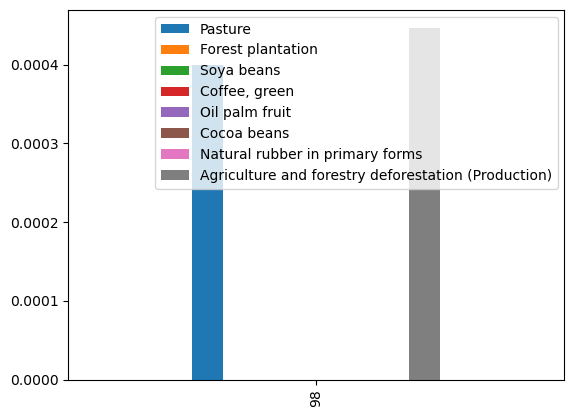

KeyboardInterrupt: Interrupted by user

In [12]:

while True:

    row = df.sample(1)
    print(row.country.values[0])
    row.plot.bar()
    plt.show()
    _waitforinput = input()

    clear_output(wait=True)
    
    



In [13]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)


In [14]:
def top_n_drivers_for_country(_country, n=10):
    sub_df = grouped_df.loc[grouped_df['Producer country'] == _country].copy(deep=True)


    total_agri_def = country_deforestation_stats.loc[country_deforestation_stats.Country == _country]['Agriculture and forestry deforestation (Production)'].values[0]

    sub_df['Deforestation attribution, unamortized (ha)'] =  sub_df['Deforestation attribution, unamortized (ha)']/total_agri_def




    return sub_df[['Producer country', 'Commodity',
           'Deforestation attribution, unamortized (ha)']]\
        .sort_values('Deforestation attribution, unamortized (ha)', ascending=False ).head(n)
    

In [15]:
#__country = np.random.choice(grouped_df['Producer country'].unique())
__country = 'Ghana'
top_n_drivers_for_country(__country)


NameError: name 'grouped_df' is not defined

### Comparison with FAOSTAT

In [3]:
faostat_df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/tmp/faostat_reports.csv')
faostat_df = faostat_df.drop('country_area', axis=1)

In [8]:
faostat_df.loc[faostat_df.country == 'Ghana']

,Cattle,Palm oil,Soya beans,Cocoa beans,"Coffee, green",Natural rubber in primary forms,country
50,0.088371,0.026197,0.0,0.715853,-0.001716,0.040297,Ghana


In [230]:
cols_without_total_def = ['Cocoa beans', 'Coffee, green', 'Forest plantation', 'Pasture',
       'Oil palm fruit', 'Soya beans', 'Natural rubber in primary forms',
       'Country']

<Axes: >

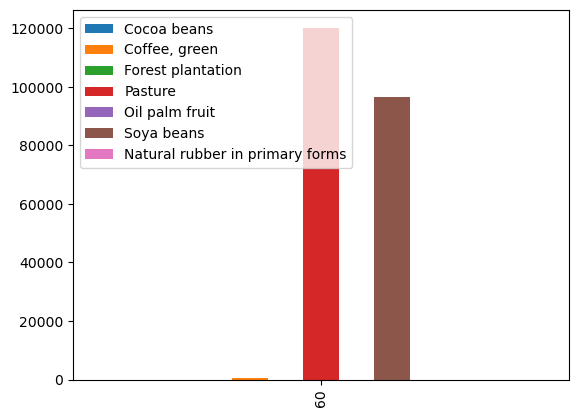

In [238]:
merged_df.loc[merged_df.Country == 'Zambia'][cols_without_total_def].plot.bar()

In [18]:
df.loc[df.country == 'Ghana']

,Pasture,Forest plantation,Soya beans,"Coffee, green",Oil palm fruit,Cocoa beans,Natural rubber in primary forms,Agriculture and forestry deforestation (Production),country
60,0.098,0.000,0.011,0.000,0.027,0.240,0.009,0.717,Ghana


In [19]:
faostat_df.loc[faostat_df.country == 'Ghana']

,Cattle,Palm oil,Soya beans,Cocoa beans,"Coffee, green",Natural rubber in primary forms,country
50,0.088,0.026,0.000,0.716,-0.002,0.040,Ghana


In [23]:
df.loc[df.country == "Côte d'Ivoire"]

,Pasture,Forest plantation,Soya beans,"Coffee, green",Oil palm fruit,Cocoa beans,Natural rubber in primary forms,Agriculture and forestry deforestation (Production),country
41,0.037,NaN,0.000,0.138,0.042,0.430,0.065,1.444,Côte d'Ivoire


In [21]:
faostat_df.loc[faostat_df.country == "Côte d'Ivoire"]

,Cattle,Palm oil,Soya beans,Cocoa beans,"Coffee, green",Natural rubber in primary forms,country
51,0.036,0.031,-0.001,1.000,-0.108,0.224,Côte d'Ivoire


In [26]:
df.loc[df.country == 'Ecuador']

,Pasture,Forest plantation,Soya beans,"Coffee, green",Oil palm fruit,Cocoa beans,Natural rubber in primary forms,Agriculture and forestry deforestation (Production),country
46,0.059,0.004,0.003,0.000,0.048,0.026,0.001,0.220,Ecuador


In [24]:
faostat_df.loc[faostat_df.country == 'Ecuador']

,Cattle,Palm oil,Soya beans,Cocoa beans,"Coffee, green",Natural rubber in primary forms,country
35,-0.016,0.042,-0.020,0.072,-0.149,0.006,Ecuador


### DeDuCe subnational statistics Brazil


In [ ]:
xx= pd.read_csv(os.path.join(path, 'Sub-national attribution (Brazil)', 'DeDuCE_Brazil_subnational_Deforestation_attribution_v1.0.0_runID-0-150.csv'))

grouped_xx = xx[['Producer country', 
        'Commodity',
       'Deforestation attribution, unamortized (ha)',
       'Deforestation risk, amortized (ha)']].groupby(['Commodity']).sum().reset_index()


grouped_xx.sort_values('Deforestation attribution, unamortized (ha)', ascending=False )

### TMP

In [29]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")

In [27]:
goldman = pd.read_csv('../data/tmp/labels_55k_goldman.csv')

In [28]:
goldman

,geometry,driver,sampleid,dataset,split,country,goldman_index
0,POINT (-80.06997418635105 -1.2140731027581488),cocoa,110000835,cocoa_ecuador.csv,4,Ecuador,[13844]
1,POINT (-3.252726923505843 6.05540773743447),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire,[12051]
2,POINT (-1.8324904593128795 6.046244921563979),cocoa,30005875,cocoa.csv,1,Ghana,[4340]
3,POINT (-6.441386856016498 5.597266943912221),cocoa,30007330,cocoa.csv,4,Côte d'Ivoire,[4680]
4,POINT (-6.212316458566018 5.624755391523431),cocoa,30007224,cocoa.csv,4,Côte d'Ivoire,[4680]
...,...,...,...,...,...,...,...
55298,POINT (76.66305108549047 10.758438413532348),urban,100002981,worldcover.csv,1,India,[40]
55299,POINT (106.68137671728651 -6.334442760971974),urban,100009782,worldcover.csv,1,Indonesia,[]
55300,POINT (-35.322382484061244 -5.749666958458276),urban,10427227,mapbiomas.csv,2,Brazil,[3903]
55301,POINT (101.5439344788162 3.154945653990399),urban,100004466,worldcover.csv,1,Malaysia,[9271]


In [31]:
labels['goldman_index'] = goldman['goldman_index']

In [32]:
labels.to_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv", index=False)